In [6]:

import pandas as pd

df_new = pd.read_csv("/content/Disease and symptoms dataset.csv")

print("Dataset shape:", df_new.shape)
print("\nColumn names:")
print(df_new.columns.tolist())

print("\nFirst 5 rows:")
display(df_new.head())

print("\nMissing values:")
print(df_new.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", df_new.duplicated().sum())


Dataset shape: (246945, 378)

Column names:
['diseases', 'anxiety and nervousness', 'depression', 'shortness of breath', 'depressive or psychotic symptoms', 'sharp chest pain', 'dizziness', 'insomnia', 'abnormal involuntary movements', 'chest tightness', 'palpitations', 'irregular heartbeat', 'breathing fast', 'hoarse voice', 'sore throat', 'difficulty speaking', 'cough', 'nasal congestion', 'throat swelling', 'diminished hearing', 'lump in throat', 'throat feels tight', 'difficulty in swallowing', 'skin swelling', 'retention of urine', 'groin mass', 'leg pain', 'hip pain', 'suprapubic pain', 'blood in stool', 'lack of growth', 'emotional symptoms', 'elbow weakness', 'back weakness', 'pus in sputum', 'symptoms of the scrotum and testes', 'swelling of scrotum', 'pain in testicles', 'flatulence', 'pus draining from ear', 'jaundice', 'mass in scrotum', 'white discharge from eye', 'irritable infant', 'abusing alcohol', 'fainting', 'hostile behavior', 'drug abuse', 'sharp abdominal pain', '

,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,...,stuttering or stammering,problems with orgasm,nose deformity,lump over jaw,sore in nose,hip weakness,back swelling,ankle stiffness or tightness,ankle weakness,neck weakness
0,panic disorder,1,0,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,panic disorder,0,0,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,panic disorder,1,1,1,1,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,panic disorder,1,0,0,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0



Missing values:
neck weakness                       0
diseases                            0
anxiety and nervousness             0
depression                          0
shortness of breath                 0
depressive or psychotic symptoms    0
sharp chest pain                    0
dizziness                           0
insomnia                            0
abnormal involuntary movements      0
chest tightness                     0
palpitations                        0
irregular heartbeat                 0
breathing fast                      0
hoarse voice                        0
dtype: int64

Duplicate rows: 57298


In [7]:

# Separate disease labels from symptom features
target_col = "diseases"
symptom_cols = [c for c in df_new.columns if c != target_col]

# Check missing values in the disease labels
print("Missing disease labels:", df_new[target_col].isna().sum())

# Check class distribution
print("\nNumber of diseases:", df_new[target_col].nunique())
print("\nExamples per disease:")
print(df_new[target_col].value_counts().describe())

print("\n10 diseases with the fewest examples:")
print(df_new[target_col].value_counts().tail(10))

# Find identical symptom profiles, ignoring the disease label
profile_counts = df_new.groupby(symptom_cols, dropna=False)[target_col].nunique()

print("\nUnique symptom profiles:", len(profile_counts))
print("Profiles linked to multiple diseases:", (profile_counts > 1).sum())

# Check whether all feature values are binary or missing
values = pd.unique(df_new[symptom_cols].to_numpy().ravel())
print("\nDistinct symptom values:", sorted(
    [str(v) for v in values]
)[:20])


Missing disease labels: 0

Number of diseases: 773

Examples per disease:
count     773.000000
mean      319.463131
std       351.691549
min         1.000000
25%        30.000000
50%       168.000000
75%       505.000000
max      1219.000000
Name: count, dtype: float64

10 diseases with the fewest examples:
diseases
heat stroke                 1
chronic ulcer               1
open wound of the knee      1
open wound of the chest     1
open wound due to trauma    1
thalassemia                 1
huntington disease          1
typhoid fever               1
kaposi sarcoma              1
turner syndrome             1
Name: count, dtype: int64

Unique symptom profiles: 169888
Profiles linked to multiple diseases: 12634

Distinct symptom values: ['0', '1']


In [8]:

# Summarize each distinct symptom profile
profile_summary = (
    df_new.groupby(symptom_cols, dropna=False)
    .agg(
        disease=(target_col, "first"),
        label_count=(target_col, "nunique"),
        original_rows=(target_col, "size")
    )
    .reset_index()
)

# Keep profiles that map to exactly one disease
clean_profiles = profile_summary[
    profile_summary["label_count"] == 1
].copy()

print("Original rows:", len(df_new))
print("Unique symptom profiles:", len(profile_summary))
print("Ambiguous profiles excluded:", (profile_summary["label_count"] > 1).sum())
print("Unambiguous profiles remaining:", len(clean_profiles))

# Count distinct usable profiles per disease
counts = clean_profiles["disease"].value_counts()

print("\nDisease count after cleaning:")
print(counts.describe())

print("\nNumber of diseases with at least 10 unique profiles:",
      (counts >= 10).sum())
print("Number with at least 20 unique profiles:",
      (counts >= 20).sum())
print("Number with at least 30 unique profiles:",
      (counts >= 30).sum())
print("Number with at least 50 unique profiles:",
      (counts >= 50).sum())

print("\nTop 15 diseases by usable profiles:")
print(counts.head(15))

print("\nBottom 15 diseases by usable profiles:")
print(counts.tail(15))

print("\nMissing symptom values:", df_new[symptom_cols].isna().sum().sum())



/tmp/ipykernel_388/2382170829.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()
/tmp/ipykernel_388/2382170829.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()
/tmp/ipykernel_388/2382170829.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()
/tmp/ipyke

Original rows: 246945
Unique symptom profiles: 169888
Ambiguous profiles excluded: 12634
Unambiguous profiles remaining: 157254

Disease count after cleaning:
count     738.000000
mean      213.081301
std       293.087145
min         1.000000
25%        10.000000
50%        68.000000
75%       290.750000
max      1190.000000
Name: count, dtype: float64

Number of diseases with at least 10 unique profiles: 558
Number with at least 20 unique profiles: 486
Number with at least 30 unique profiles: 440
Number with at least 50 unique profiles: 393

Top 15 diseases by usable profiles:
disease
hypoglycemia                          1190
obstructive sleep apnea (osa)         1182
bursitis                              1177
concussion                            1175
liver disease                         1166
injury to the leg                     1156
arthritis of the hip                  1155
injury to the arm                     1150
benign prostatic hyperplasia (bph)    1149
gout                

In [9]:

import pandas as pd
import numpy as np

# Keep diseases with at least 30 distinct symptom profiles
MIN_PROFILES = 30

disease_counts = clean_profiles["disease"].value_counts()
eligible_diseases = disease_counts[
    disease_counts >= MIN_PROFILES
].index

data = clean_profiles[
    clean_profiles["disease"].isin(eligible_diseases)
].copy()

# Extract features and target
X = data[symptom_cols].copy()
y = data["disease"].copy()
'''# Reuse the cleaned, imputed features from Cell 3
X = X.copy()
y = y.copy()'''

# Convert symptom values to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Check missing values before handling them
print("Missing values before cleaning:", X.isna().sum().sum())

# Since symptoms are binary, impute missing values using
# each feature's most frequent value
for col in X.columns:
    if X[col].isna().any():
        X[col] = X[col].fillna(X[col].mode().iloc[0])

# Convert remaining values to integers
X = X.astype(int)

print("\nFinal dataset shape:", X.shape)
print("Number of diseases:", y.nunique())
print("Minimum profiles per disease:", y.value_counts().min())
print("Maximum profiles per disease:", y.value_counts().max())
print("\nClass distribution:")
print(y.value_counts().describe())


Missing values before cleaning: 0

Final dataset shape: (154489, 377)
Number of diseases: 440
Minimum profiles per disease: 30
Maximum profiles per disease: 1190

Class distribution:
count     440.000000
mean      351.111364
std       311.244177
min        30.000000
25%       106.500000
50%       255.500000
75%       498.750000
max      1190.000000
Name: count, dtype: float64


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Encode disease names as numeric labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# One shared, stratified split for both models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of symptom features:", X_train.shape[1])
print("Diseases in training:", len(set(y_train)))
print("Diseases in testing:", len(set(y_test)))

# Verify that every disease is represented in both sets
print("Classes missing from training:",
      len(set(y_test) - set(y_train)))


Training samples: 123591
Testing samples: 30898
Number of symptom features: 377
Diseases in training: 440
Diseases in testing: 440
Classes missing from training: 0


In [11]:

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Scale using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

nn_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)
nn_pred = nn_model.predict(X_test_scaled)

nn_accuracy = accuracy_score(y_test, nn_pred)
nn_macro_f1 = f1_score(y_test, nn_pred, average="macro")
nn_weighted_f1 = f1_score(y_test, nn_pred, average="weighted")

print("NEURAL NETWORK RESULTS")
print("----------------------")
print(f"Accuracy:    {nn_accuracy:.4f}")
print(f"Macro F1:    {nn_macro_f1:.4f}")
print(f"Weighted F1: {nn_weighted_f1:.4f}")
print("Iterations:", nn_model.n_iter_)
print("Converged:", not nn_model.n_iter_ == 100)


NEURAL NETWORK RESULTS
----------------------
Accuracy:    0.9415
Macro F1:    0.9386
Weighted F1: 0.9413
Iterations: 25
Converged: True


In [12]:

import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Recreate features and labels
X = data[symptom_cols].copy()
y = data["disease"].copy()

# Encode disease labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Reproducible split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Store everything needed for model development
fuzzymed_data = {
    "X_train": X_train.to_numpy(dtype=np.float32),
    "X_test": X_test.to_numpy(dtype=np.float32),
    "y_train": np.asarray(y_train),
    "y_test": np.asarray(y_test),
    "symptom_cols": list(X.columns),
    "disease_names": label_encoder.classes_,
    "label_encoder": label_encoder
}

with open("/content/fuzzymed_data.pkl", "wb") as f:
    pickle.dump(fuzzymed_data, f)

print("Saved: /content/fuzzymed_data.pkl")
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("Symptoms:", len(symptom_cols))
print("Diseases:", len(label_encoder.classes_))


Saved: /content/fuzzymed_data.pkl
Training samples: 123591
Testing samples: 30898
Symptoms: 377
Diseases: 440


In [13]:

import pickle

with open("/content/fuzzymed_data.pkl", "rb") as f:
    fuzzymed_data = pickle.load(f)

Xtr = fuzzymed_data["X_train"]
Xte = fuzzymed_data["X_test"]
ytr = fuzzymed_data["y_train"]
yte = fuzzymed_data["y_test"]

symptom_cols = fuzzymed_data["symptom_cols"]
disease_names = fuzzymed_data["disease_names"]
label_encoder = fuzzymed_data["label_encoder"]

print("Data loaded successfully!")
print("Training:", Xtr.shape)
print("Testing:", Xte.shape)
print("Diseases:", len(disease_names))


Data loaded successfully!
Training: (123591, 377)
Testing: (30898, 377)
Diseases: 440


In [14]:
from google.colab import files
files.download("/content/fuzzymed_data.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import numpy as np

X = np.asarray(Xtr)
y = np.asarray(ytr)
classes = np.unique(y)

for cls in classes:
    profiles = X[y == cls]

    print(
        f"Class {cls}: "
        f"{len(profiles)} profiles, "
        f"mean active symptoms = {profiles.sum(axis=1).mean():.2f}"
    )

Class 0: 30 profiles, mean active symptoms = 3.87
Class 1: 201 profiles, mean active symptoms = 5.79
Class 2: 88 profiles, mean active symptoms = 4.86
Class 3: 102 profiles, mean active symptoms = 4.73
Class 4: 153 profiles, mean active symptoms = 5.31
Class 5: 459 profiles, mean active symptoms = 6.15
Class 6: 889 profiles, mean active symptoms = 6.22
Class 7: 759 profiles, mean active symptoms = 6.46
Class 8: 436 profiles, mean active symptoms = 6.14
Class 9: 28 profiles, mean active symptoms = 5.46
Class 10: 615 profiles, mean active symptoms = 5.88
Class 11: 306 profiles, mean active symptoms = 5.52
Class 12: 874 profiles, mean active symptoms = 6.26
Class 13: 191 profiles, mean active symptoms = 5.15
Class 14: 548 profiles, mean active symptoms = 6.04
Class 15: 584 profiles, mean active symptoms = 5.90
Class 16: 178 profiles, mean active symptoms = 5.35
Class 17: 206 profiles, mean active symptoms = 5.08
Class 18: 113 profiles, mean active symptoms = 4.81
Class 19: 394 profiles, m

In [25]:
for cls in classes:
    profiles = Xtr[ytr == cls]
    print(
        f"Class {cls}: "
        f"{len(profiles)} profiles, "
        f"mean active symptoms = {profiles.sum(axis=1).mean():.2f}"
    )

Class 0: 30 profiles, mean active symptoms = 3.87
Class 1: 201 profiles, mean active symptoms = 5.79
Class 2: 88 profiles, mean active symptoms = 4.86
Class 3: 102 profiles, mean active symptoms = 4.73
Class 4: 153 profiles, mean active symptoms = 5.31
Class 5: 459 profiles, mean active symptoms = 6.15
Class 6: 889 profiles, mean active symptoms = 6.22
Class 7: 759 profiles, mean active symptoms = 6.46
Class 8: 436 profiles, mean active symptoms = 6.14
Class 9: 28 profiles, mean active symptoms = 5.46
Class 10: 615 profiles, mean active symptoms = 5.88
Class 11: 306 profiles, mean active symptoms = 5.52
Class 12: 874 profiles, mean active symptoms = 6.26
Class 13: 191 profiles, mean active symptoms = 5.15
Class 14: 548 profiles, mean active symptoms = 6.04
Class 15: 584 profiles, mean active symptoms = 5.90
Class 16: 178 profiles, mean active symptoms = 5.35
Class 17: 206 profiles, mean active symptoms = 5.08
Class 18: 113 profiles, mean active symptoms = 4.81
Class 19: 394 profiles, m

In [26]:
import numpy as np

print("NaNs in training features:", np.isnan(Xtr).sum())
print("NaNs in test features:", np.isnan(Xte).sum())
print("Infinite values in training:", np.isinf(Xtr).sum())
print("Infinite values in testing:", np.isinf(Xte).sum())

NaNs in training features: 0
NaNs in test features: 0
Infinite values in training: 0
Infinite values in testing: 0


In [27]:
Xtr = np.nan_to_num(Xtr, nan=0.0, posinf=0.0, neginf=0.0)
Xte = np.nan_to_num(Xte, nan=0.0, posinf=0.0, neginf=0.0)

print("Remaining NaNs:", np.isnan(Xtr).sum() + np.isnan(Xte).sum())

Remaining NaNs: 0


In [29]:
print("Fuzzy predictions exist:", "fuzzy_pred" in globals())
print("NN predictions exist:", "nn_pred" in globals())
print("Classes:", len(np.unique(ytr)))

Fuzzy predictions exist: False
NN predictions exist: True
Classes: 440


In [31]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

X_train = np.nan_to_num(
    np.asarray(Xtr, dtype=np.float32),
    nan=0.0, posinf=0.0, neginf=0.0
)
X_test = np.nan_to_num(
    np.asarray(Xte, dtype=np.float32),
    nan=0.0, posinf=0.0, neginf=0.0
)

y_train = np.asarray(ytr)
y_test = np.asarray(yte)

classes = np.unique(y_train)

# Build one prototype per disease using training data
prototypes = np.vstack([
    X_train[y_train == cls].mean(axis=0)
    for cls in classes
]).astype(np.float32)

prototype_sums = prototypes.sum(axis=1)
fuzzy_pred = np.empty(len(X_test), dtype=y_train.dtype)

# Predict using fuzzy Jaccard similarity
batch_size = 512

for start in range(0, len(X_test), batch_size):
    end = min(start + batch_size, len(X_test))
    batch = X_test[start:end]

    intersection = batch @ prototypes.T
    union = (
        batch.sum(axis=1, keepdims=True)
        + prototype_sums[None, :]
        - intersection
    )

    similarity = np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )

    fuzzy_pred[start:end] = classes[
        np.argmax(similarity, axis=1)
    ]

print("Fuzzy predictions recreated:", len(fuzzy_pred))
print("Fuzzy accuracy:", accuracy_score(y_test, fuzzy_pred))
print("Fuzzy macro F1:", f1_score(
    y_test, fuzzy_pred, average="macro", zero_division=0
))
print("Fuzzy weighted F1:", f1_score(
    y_test, fuzzy_pred, average="weighted", zero_division=0
))

Fuzzy predictions recreated: 30898
Fuzzy accuracy: 0.9189267913780828
Fuzzy macro F1: 0.8932438838493416
Fuzzy weighted F1: 0.9252582432853712


In [32]:
print("Xtr:", Xtr.shape)
print("Xte:", Xte.shape)
print("ytr:", len(ytr))
print("yte:", len(yte))
print("fuzzy_pred:", len(fuzzy_pred))
print("NN predictions:", len(nn_pred))
print("Unique diseases:", len(np.unique(ytr)))

Xtr: (123591, 377)
Xte: (30898, 377)
ytr: 123591
yte: 30898
fuzzy_pred: 30898
NN predictions: 30898
Unique diseases: 440


In [33]:
print("Test samples:", len(yte))
print("Fuzzy predictions:", len(fuzzy_pred))
print("NN predictions:", len(nn_pred))

Test samples: 30898
Fuzzy predictions: 30898
NN predictions: 30898


In [34]:

import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Convert features to numeric arrays
X_train = np.nan_to_num(
    np.asarray(Xtr, dtype=np.float32),
    nan=0.0, posinf=0.0, neginf=0.0
)
X_test = np.nan_to_num(
    np.asarray(Xte, dtype=np.float32),
    nan=0.0, posinf=0.0, neginf=0.0
)

y_train = np.asarray(ytr)
y_test = np.asarray(yte)

# Get all disease classes
classes = np.unique(y_train)

# Create one fuzzy symptom prototype per disease.
# Each value represents the fraction of training patients
# in that disease class who have the corresponding symptom.
prototypes = np.vstack([
    X_train[y_train == disease].mean(axis=0)
    for disease in classes
]).astype(np.float32)

# Precompute prototype symptom totals
prototype_sums = prototypes.sum(axis=1)

# Predict using fuzzy Jaccard similarity
fuzzy_pred = np.empty(len(X_test), dtype=classes.dtype)
batch_size = 512

for start in range(0, len(X_test), batch_size):
    end = min(start + batch_size, len(X_test))
    batch = X_test[start:end]

    # Similarity between test samples and disease prototypes
    intersection = batch @ prototypes.T

    union = (
        batch.sum(axis=1, keepdims=True)
        + prototype_sums[None, :]
        - intersection
    )

    similarity = np.divide(
        intersection,
        union,
        out=np.zeros_like(intersection),
        where=union > 0
    )

    # Select the disease with the highest similarity
    best_indices = np.argmax(similarity, axis=1)
    fuzzy_pred[start:end] = classes[best_indices]

print("Fuzzy predictions completed!")
print("Test samples:", len(y_test))
print("Fuzzy predictions:", len(fuzzy_pred))
print("Unique predicted diseases:", len(np.unique(fuzzy_pred)))

print("\nFuzzy Accuracy:", accuracy_score(y_test, fuzzy_pred))
print("Fuzzy Macro F1:", f1_score(
    y_test, fuzzy_pred, average="macro", zero_division=0
))
print("Fuzzy Weighted F1:", f1_score(
    y_test, fuzzy_pred, average="weighted", zero_division=0
))


Fuzzy predictions completed!
Test samples: 30898
Fuzzy predictions: 30898
Unique predicted diseases: 440

Fuzzy Accuracy: 0.9189267913780828
Fuzzy Macro F1: 0.8932438838493416
Fuzzy Weighted F1: 0.9252582432853712


In [35]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Ensure both models are evaluated on the same test set
assert len(yte) == len(nn_pred) == len(fuzzy_pred), \
    "Prediction lengths do not match!"

comparison = pd.DataFrame({
    "Model": ["Neural Network", "Fuzzy Logic"],
    "Accuracy": [
        accuracy_score(yte, nn_pred),
        accuracy_score(yte, fuzzy_pred)
    ],
    "Macro F1": [
        f1_score(yte, nn_pred, average="macro", zero_division=0),
        f1_score(yte, fuzzy_pred, average="macro", zero_division=0)
    ],
    "Weighted F1": [
        f1_score(yte, nn_pred, average="weighted", zero_division=0),
        f1_score(yte, fuzzy_pred, average="weighted", zero_division=0)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Macro F1,Weighted F1
0,Neural Network,0.9415,0.9386,0.9413
1,Fuzzy Logic,0.9189,0.8932,0.9253


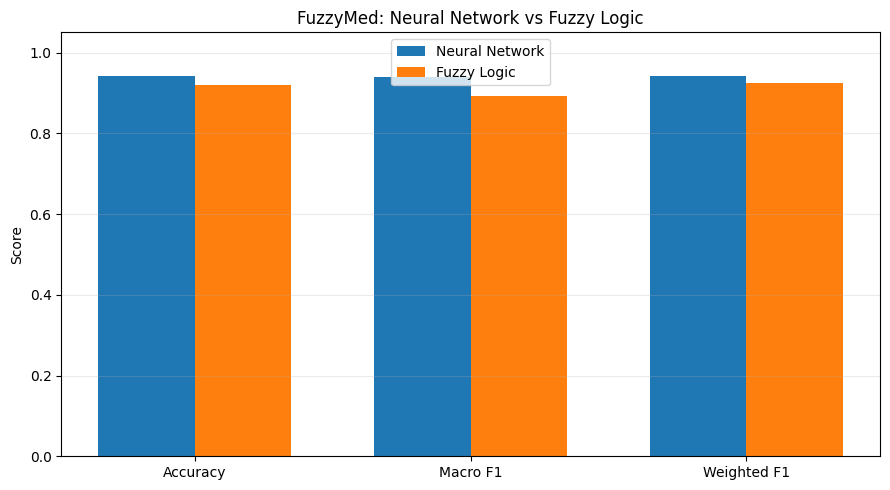

In [36]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Macro F1", "Weighted F1"]
nn_scores = [0.9415, 0.9386, 0.9413]
fuzzy_scores = [0.9189, 0.8932, 0.9253]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, nn_scores, width, label="Neural Network")
plt.bar(x + width/2, fuzzy_scores, width, label="Fuzzy Logic")

plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("FuzzyMed: Neural Network vs Fuzzy Logic")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [37]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    yte,
    nn_pred,
    output_dict=True,
    zero_division=0
)

nn_report = pd.DataFrame(report).T
display(nn_report.round(3))

,precision,recall,f1-score,support
0,1.000,1.000,1.000,7.000
1,0.980,0.960,0.970,50.000
2,1.000,0.773,0.872,22.000
3,0.960,0.960,0.960,25.000
4,0.925,0.974,0.949,38.000
...,...,...,...,...
438,1.000,0.925,0.961,53.000
439,1.000,0.981,0.990,53.000
accuracy,0.941,0.941,0.941,0.941
macro avg,0.948,0.935,0.939,30898.000


In [38]:

from sklearn.metrics import classification_report
import pandas as pd

fuzzy_report = classification_report(
    yte,
    fuzzy_pred,
    output_dict=True,
    zero_division=0
)

fuzzy_report_df = pd.DataFrame(fuzzy_report).T
display(fuzzy_report_df.round(3))


,precision,recall,f1-score,support
0,0.389,1.000,0.560,7.000
1,0.980,0.980,0.980,50.000
2,0.468,1.000,0.638,22.000
3,0.697,0.920,0.793,25.000
4,0.925,0.974,0.949,38.000
...,...,...,...,...
438,0.981,0.962,0.971,53.000
439,0.929,0.981,0.954,53.000
accuracy,0.919,0.919,0.919,0.919
macro avg,0.867,0.954,0.893,30898.000


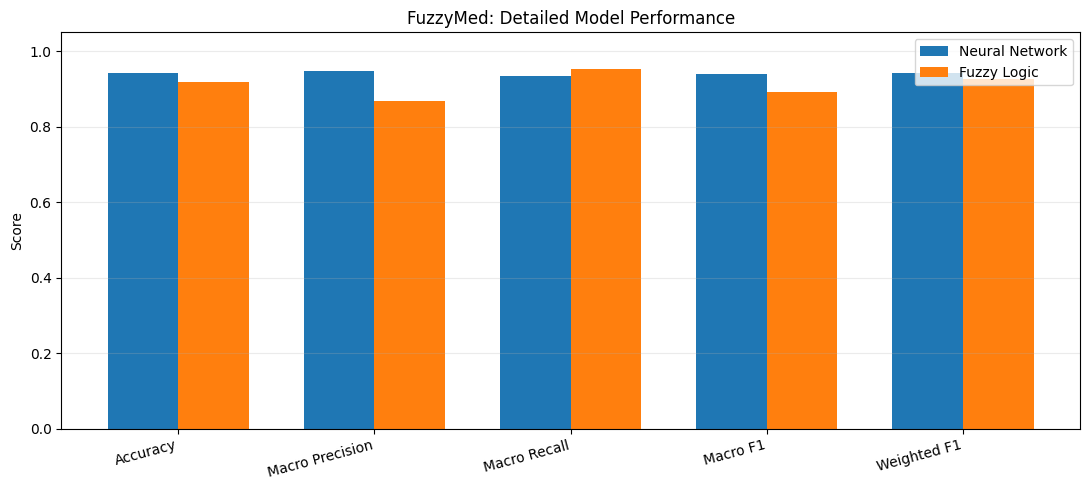

In [39]:

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy", "Macro Precision", "Macro Recall",
    "Macro F1", "Weighted F1"
]

nn_scores = [0.9415, 0.948, 0.935, 0.9386, 0.9413]
fuzzy_scores = [0.9189, 0.867, 0.954, 0.8932, 0.9253]

x = np.arange(len(metrics))
width = 0.36

plt.figure(figsize=(11, 5))
plt.bar(x - width/2, nn_scores, width, label="Neural Network")
plt.bar(x + width/2, fuzzy_scores, width, label="Fuzzy Logic")

plt.xticks(x, metrics, rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("FuzzyMed: Detailed Model Performance")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [40]:

import pandas as pd
from sklearn.metrics import classification_report

# Generate reports
nn_dict = classification_report(
    yte, nn_pred, output_dict=True, zero_division=0
)
fuzzy_dict = classification_report(
    yte, fuzzy_pred, output_dict=True, zero_division=0
)

# Keep only disease-class entries (skip accuracy and averages)
class_ids = [
    k for k, v in nn_dict.items()
    if isinstance(v, dict)
    and "f1-score" in v
    and k in fuzzy_dict
    and isinstance(fuzzy_dict[k], dict)
    and "f1-score" in fuzzy_dict[k]
]

# Build the comparison table
comparison_by_class = pd.DataFrame({
    "NN_F1": {
        k: nn_dict[k]["f1-score"] for k in class_ids
    },
    "Fuzzy_F1": {
        k: fuzzy_dict[k]["f1-score"] for k in class_ids
    }
})

comparison_by_class["F1_Difference"] = (
    comparison_by_class["NN_F1"]
    - comparison_by_class["Fuzzy_F1"]
)

print("Classes where Fuzzy Logic performs better:")
display(
    comparison_by_class
    .sort_values("F1_Difference")
    .head(10)
    .round(3)
)

print("Classes where Neural Network performs better:")
display(
    comparison_by_class
    .sort_values("F1_Difference", ascending=False)
    .head(10)
    .round(3)
)


Classes where Fuzzy Logic performs better:


,NN_F1,Fuzzy_F1,F1_Difference
243,0.769,0.941,-0.172
366,0.308,0.444,-0.137
105,0.903,1.000,-0.097
67,0.909,1.000,-0.091
416,0.917,1.000,-0.083
372,0.586,0.662,-0.076
118,0.842,0.917,-0.075
116,0.560,0.629,-0.069
146,0.938,1.000,-0.062
289,0.903,0.966,-0.062


Classes where Neural Network performs better:


,NN_F1,Fuzzy_F1,F1_Difference
306,1.000,0.293,0.707
344,1.000,0.326,0.674
234,0.857,0.189,0.668
384,0.933,0.302,0.631
9,0.923,0.368,0.555
220,1.000,0.526,0.474
310,1.000,0.538,0.462
0,1.000,0.560,0.440
321,1.000,0.588,0.412
313,0.960,0.558,0.402


In [41]:

# Inspect how your class labels map to disease names
print("Label encoder available:", "label_encoder" in globals())

if "label_encoder" in globals():
    print("Example mappings:")
    for i in [243, 366, 306, 344, 234]:
        if i < len(label_encoder.classes_):
            print(i, "->", label_encoder.classes_[i])
else:
    print("Disease names may be available in disease_names.")
    print("Example:", disease_names[:5])


Label encoder available: True
Example mappings:
243 -> lactose intolerance
366 -> sick sinus syndrome
306 -> pericarditis
344 -> pulmonary fibrosis
234 -> ischemia of the bowel


In [42]:


# Keep only rows representing disease class IDs
comparison_by_class = comparison_by_class[
    comparison_by_class.index.astype(str).str.isdigit()
].copy()

# Map numeric IDs to actual disease names
comparison_by_class["Disease"] = [
    label_encoder.classes_[int(class_id)]
    for class_id in comparison_by_class.index
]

# Put disease names first
comparison_by_class = comparison_by_class[
    ["Disease", "NN_F1", "Fuzzy_F1", "F1_Difference"]
]

print("Diseases where Fuzzy Logic performs better:")
display(
    comparison_by_class
    .sort_values("F1_Difference")
    .head(10)
    .round(3)
)

print("Diseases where Neural Network performs better:")
display(
    comparison_by_class
    .sort_values("F1_Difference", ascending=False)
    .head(10)
    .round(3)
)

# Save the complete comparison
comparison_by_class.to_csv(
    "FuzzyMed_Disease_Class_Comparison.csv",
    index=True
)

print("Saved FuzzyMed_Disease_Class_Comparison.csv")


Diseases where Fuzzy Logic performs better:


,Disease,NN_F1,Fuzzy_F1,F1_Difference
243,lactose intolerance,0.769,0.941,-0.172
366,sick sinus syndrome,0.308,0.444,-0.137
105,deep vein thrombosis (dvt),0.903,1.000,-0.097
67,cellulitis or abscess of mouth,0.909,1.000,-0.091
416,trigeminal neuralgia,0.917,1.000,-0.083
372,skin pigmentation disorder,0.586,0.662,-0.076
118,dislocation of the elbow,0.842,0.917,-0.075
116,diabetic retinopathy,0.560,0.629,-0.069
146,female genitalia infection,0.938,1.000,-0.062
289,osteomyelitis,0.903,0.966,-0.062


Diseases where Neural Network performs better:


,Disease,NN_F1,Fuzzy_F1,F1_Difference
306,pericarditis,1.000,0.293,0.707
344,pulmonary fibrosis,1.000,0.326,0.674
234,ischemia of the bowel,0.857,0.189,0.668
384,stomach cancer,0.933,0.302,0.631
9,acute glaucoma,0.923,0.368,0.555
220,injury to the hand,1.000,0.526,0.474
310,perirectal infection,1.000,0.538,0.462
0,abdominal aortic aneurysm,1.000,0.560,0.440
321,poisoning due to gas,1.000,0.588,0.412
313,persistent vomiting of unknown cause,0.960,0.558,0.402


Saved FuzzyMed_Disease_Class_Comparison.csv


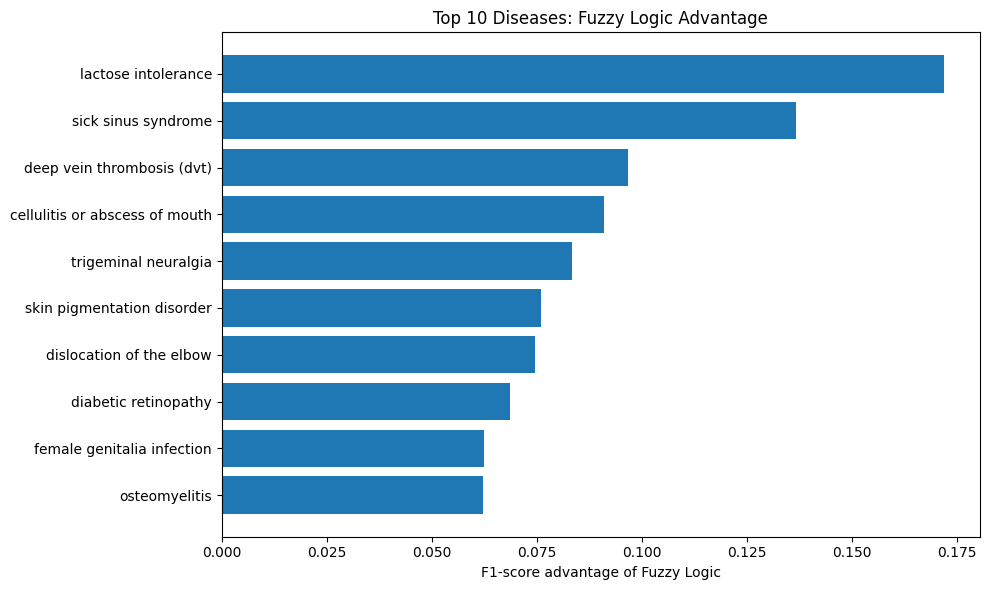

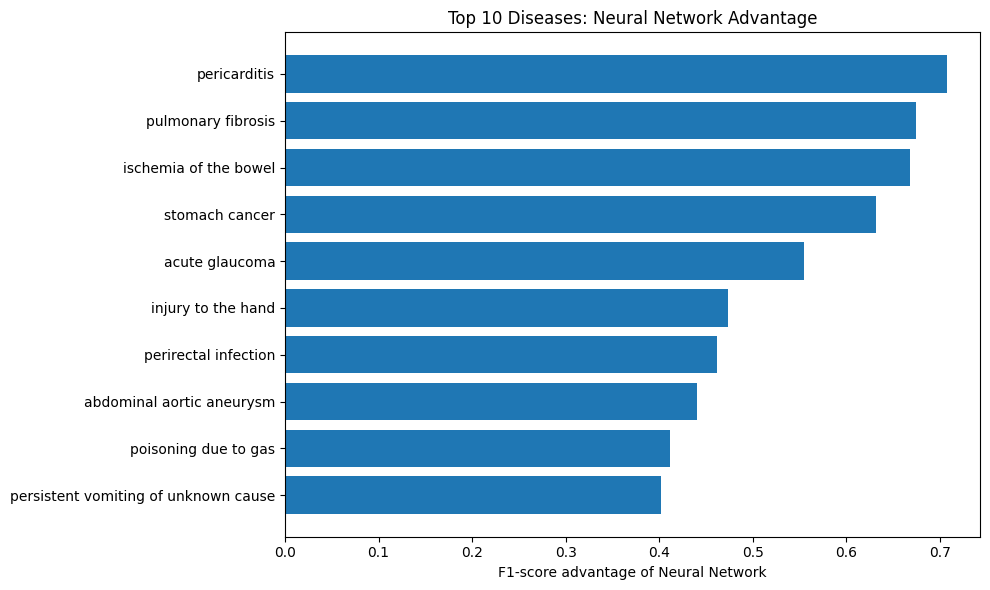

In [43]:

import matplotlib.pyplot as plt

# Largest Fuzzy Logic advantages
fuzzy_better = comparison_by_class.nsmallest(10, "F1_Difference")

plt.figure(figsize=(10, 6))
plt.barh(fuzzy_better["Disease"], -fuzzy_better["F1_Difference"])
plt.xlabel("F1-score advantage of Fuzzy Logic")
plt.title("Top 10 Diseases: Fuzzy Logic Advantage")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Largest Neural Network advantages
nn_better = comparison_by_class.nlargest(10, "F1_Difference")

plt.figure(figsize=(10, 6))
plt.barh(nn_better["Disease"], nn_better["F1_Difference"])
plt.xlabel("F1-score advantage of Neural Network")
plt.title("Top 10 Diseases: Neural Network Advantage")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [44]:

import pandas as pd
import numpy as np

# Count actual test examples for each disease
support = pd.Series(yte).value_counts()

# Add class support to the existing comparison table
comparison_by_class["Test_Samples"] = [
    int(support.get(int(class_id), 0))
    for class_id in comparison_by_class.index
]

# Show the most notable differences, along with sample counts
print("Largest Neural Network advantages:")
display(
    comparison_by_class
    .sort_values("F1_Difference", ascending=False)
    [["Disease", "NN_F1", "Fuzzy_F1",
      "F1_Difference", "Test_Samples"]]
    .head(10)
    .round(3)
)

print("Largest Fuzzy Logic advantages:")
display(
    comparison_by_class
    .sort_values("F1_Difference")
    [["Disease", "NN_F1", "Fuzzy_F1",
      "F1_Difference", "Test_Samples"]]
    .head(10)
    .round(3)
)


Largest Neural Network advantages:


,Disease,NN_F1,Fuzzy_F1,F1_Difference,Test_Samples
306,pericarditis,1.000,0.293,0.707,6
344,pulmonary fibrosis,1.000,0.326,0.674,7
234,ischemia of the bowel,0.857,0.189,0.668,7
384,stomach cancer,0.933,0.302,0.631,8
9,acute glaucoma,0.923,0.368,0.555,7
220,injury to the hand,1.000,0.526,0.474,10
310,perirectal infection,1.000,0.538,0.462,7
0,abdominal aortic aneurysm,1.000,0.560,0.440,7
321,poisoning due to gas,1.000,0.588,0.412,10
313,persistent vomiting of unknown cause,0.960,0.558,0.402,12


Largest Fuzzy Logic advantages:


,Disease,NN_F1,Fuzzy_F1,F1_Difference,Test_Samples
243,lactose intolerance,0.769,0.941,-0.172,8
366,sick sinus syndrome,0.308,0.444,-0.137,10
105,deep vein thrombosis (dvt),0.903,1.000,-0.097,16
67,cellulitis or abscess of mouth,0.909,1.000,-0.091,12
416,trigeminal neuralgia,0.917,1.000,-0.083,13
372,skin pigmentation disorder,0.586,0.662,-0.076,60
118,dislocation of the elbow,0.842,0.917,-0.075,11
116,diabetic retinopathy,0.560,0.629,-0.069,11
146,female genitalia infection,0.938,1.000,-0.062,15
289,osteomyelitis,0.903,0.966,-0.062,14


Number of disease classes: 440
Minimum test samples per disease: 6
Median test samples per disease: 51.0
Maximum test samples per disease: 238

Classes with fewer than 10 test samples: 44
Classes with fewer than 20 test samples: 106


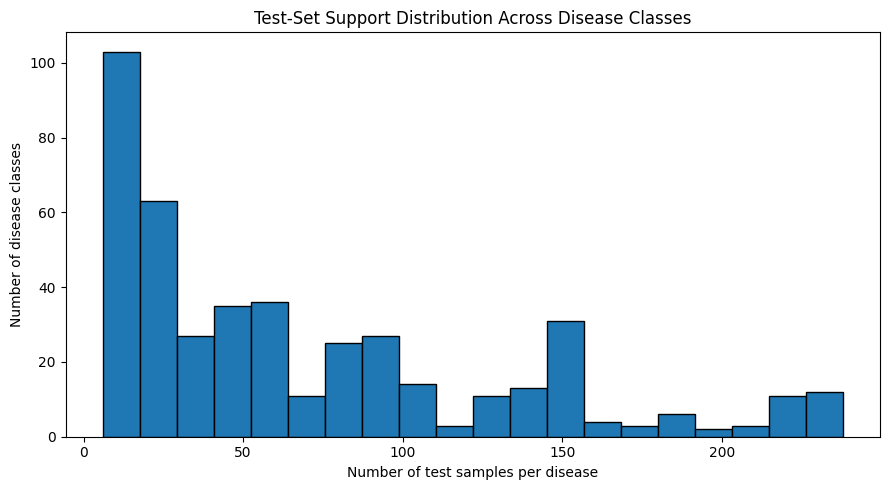

In [45]:

import matplotlib.pyplot as plt
import numpy as np

# Count test samples for every disease
support = np.asarray([
    np.sum(np.asarray(yte) == disease)
    for disease in np.unique(yte)
])

print("Number of disease classes:", len(support))
print("Minimum test samples per disease:", support.min())
print("Median test samples per disease:", np.median(support))
print("Maximum test samples per disease:", support.max())

print("\nClasses with fewer than 10 test samples:",
      np.sum(support < 10))
print("Classes with fewer than 20 test samples:",
      np.sum(support < 20))

plt.figure(figsize=(9, 5))
plt.hist(support, bins=20, edgecolor="black")
plt.xlabel("Number of test samples per disease")
plt.ylabel("Number of disease classes")
plt.title("Test-Set Support Distribution Across Disease Classes")
plt.tight_layout()
plt.show()


In [46]:

import pandas as pd
import numpy as np

# Add each disease's test-set support
support_counts = pd.Series(yte).value_counts()
class_results = comparison_by_class.copy()

class_results["Test_Samples"] = [
    int(support_counts.get(int(class_id), 0))
    for class_id in class_results.index
]

# Group diseases by number of test examples
class_results["Support_Group"] = pd.cut(
    class_results["Test_Samples"],
    bins=[0, 19, 49, 99, float("inf")],
    labels=["1–19", "20–49", "50–99", "100+"]
)

# Compare average class-level F1 scores within each group
group_results = class_results.groupby(
    "Support_Group", observed=False
)[["NN_F1", "Fuzzy_F1"]].mean()

group_results["NN_minus_Fuzzy"] = (
    group_results["NN_F1"] - group_results["Fuzzy_F1"]
)

print("Mean class-wise F1 by test-set support group:")
display(group_results.round(3))



Mean class-wise F1 by test-set support group:


,NN_F1,Fuzzy_F1,NN_minus_Fuzzy
Support_Group,,,
1–19,0.933,0.799,0.134
20–49,0.942,0.899,0.042
50–99,0.941,0.941,-0.001
100+,0.939,0.926,0.013


In [47]:

import numpy as np

print("=== DATA SPLIT CHECK ===")
print("Training features:", Xtr.shape)
print("Training labels:", np.asarray(ytr).shape)
print("Testing features:", Xte.shape)
print("Testing labels:", np.asarray(yte).shape)

print("\n=== MODEL PREDICTION CHECK ===")
print("Test samples:", len(yte))
print("Neural Network predictions:", len(nn_pred))
print("Fuzzy Logic predictions:", len(fuzzy_pred))

assert len(Xtr) == len(ytr), "Training feature/label mismatch!"
assert len(Xte) == len(yte), "Test feature/label mismatch!"
assert len(nn_pred) == len(yte), "NN prediction length mismatch!"
assert len(fuzzy_pred) == len(yte), "Fuzzy prediction length mismatch!"

print("\nPASS: Both models have predictions for every test sample.")
print("Note: This checks prediction lengths, not the full split history.")


=== DATA SPLIT CHECK ===
Training features: (123591, 377)
Training labels: (123591,)
Testing features: (30898, 377)
Testing labels: (30898,)

=== MODEL PREDICTION CHECK ===
Test samples: 30898
Neural Network predictions: 30898
Fuzzy Logic predictions: 30898

PASS: Both models have predictions for every test sample.
Note: This checks prediction lengths, not the full split history.


In [48]:

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("=== PREPROCESSING OBJECTS ===")

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, (StandardScaler, MinMaxScaler, SimpleImputer, Pipeline)):
        found = True
        print(f"\nVariable: {name}")
        print(f"Type: {type(obj).__name__}")

        if hasattr(obj, "n_features_in_"):
            print("Features fitted:", obj.n_features_in_)

        if hasattr(obj, "mean_"):
            print("Scaler/imputer fitted mean available")

        if hasattr(obj, "statistics_"):
            print("Imputation statistics available")

        if hasattr(obj, "named_steps"):
            print("Pipeline steps:", list(obj.named_steps.keys()))

if not found:
    print("No common sklearn preprocessing objects found.")
    print("Preprocessing may have been performed manually or in another cell.")


=== PREPROCESSING OBJECTS ===

Variable: scaler
Type: StandardScaler
Features fitted: 377
Scaler/imputer fitted mean available


In [49]:

print("Scaler fitted on:", scaler.n_samples_seen_, "samples")
print("Current training samples:", len(Xtr))
print("Current test samples:", len(Xte))

if np.isscalar(scaler.n_samples_seen_):
    if scaler.n_samples_seen_ == len(Xtr):
        print("\nLikely fitted on the training set size.")
    elif scaler.n_samples_seen_ == len(Xtr) + len(Xte):
        print("\nWARNING: Fitted on the combined train and test size.")
    else:
        print("\nSample count does not match either size.")
        print("We need to inspect the preprocessing code.")
else:
    print("\nScaler has per-feature sample counts; inspect preprocessing code.")


Scaler fitted on: 123591 samples
Current training samples: 123591
Current test samples: 30898

Likely fitted on the training set size.


In [50]:

# Compare current neural-network and fuzzy-model test data
print("X_test shape:", X_test.shape)
print("Xte shape:", np.asarray(Xte).shape)

print("y_test shape:", np.asarray(y_test).shape)
print("yte shape:", np.asarray(yte).shape)

if (
    np.array_equal(np.asarray(X_test), np.asarray(Xte))
    and np.array_equal(np.asarray(y_test), np.asarray(yte))
):
    print("\nPASS: Both workflows use the exact same test features and labels.")
else:
    print("\nWARNING: The test sets differ. Do not compare scores yet.")


X_test shape: (30898, 377)
Xte shape: (30898, 377)
y_test shape: (30898,)
yte shape: (30898,)

PASS: Both workflows use the exact same test features and labels.


In [51]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Ground-truth labels and current predictions
y_true = np.asarray(yte)
nn_predictions = np.asarray(nn_pred)
fuzzy_predictions = np.asarray(fuzzy_pred)

# Verify that predictions align with the same test labels
assert len(y_true) == len(nn_predictions) == len(fuzzy_predictions)
assert np.array_equal(np.asarray(y_test), y_true)

# Calculate metrics directly
results = []

for name, predictions in [
    ("Neural Network", nn_predictions),
    ("Fuzzy Logic", fuzzy_predictions)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, predictions, average="weighted", zero_division=0
        )
    })

final_results = pd.DataFrame(results).set_index("Model")

print("FINAL FUZZYMED EVALUATION")
display(final_results.round(4))

# Save the results for your report
final_results.to_csv("FuzzyMed_Final_Evaluation.csv")
print("Saved FuzzyMed_Final_Evaluation.csv")


FINAL FUZZYMED EVALUATION


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Neural Network,0.9415,0.9476,0.9352,0.9386,0.9413
Fuzzy Logic,0.9189,0.8673,0.9539,0.8932,0.9253


Saved FuzzyMed_Final_Evaluation.csv


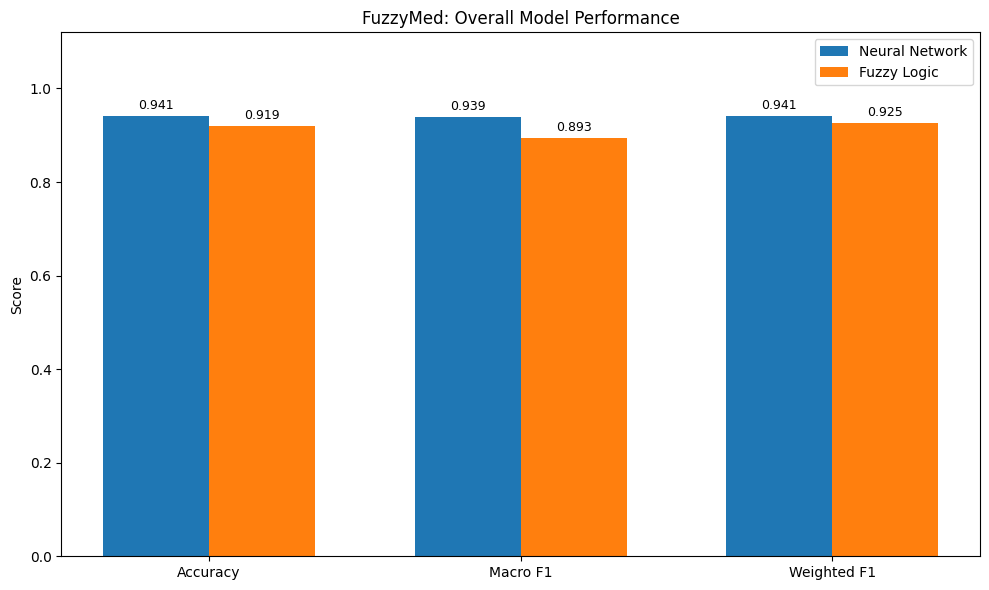

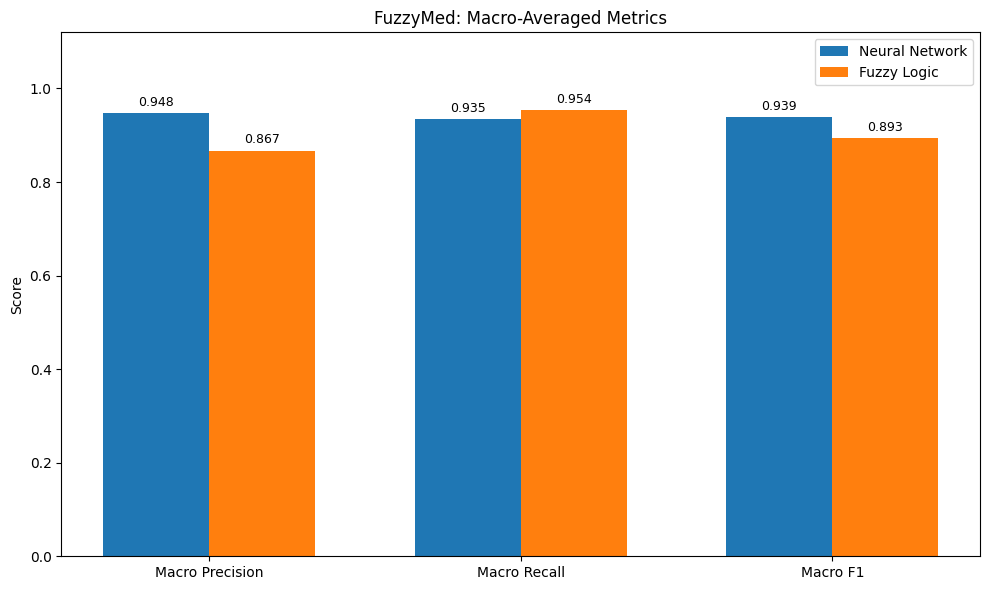

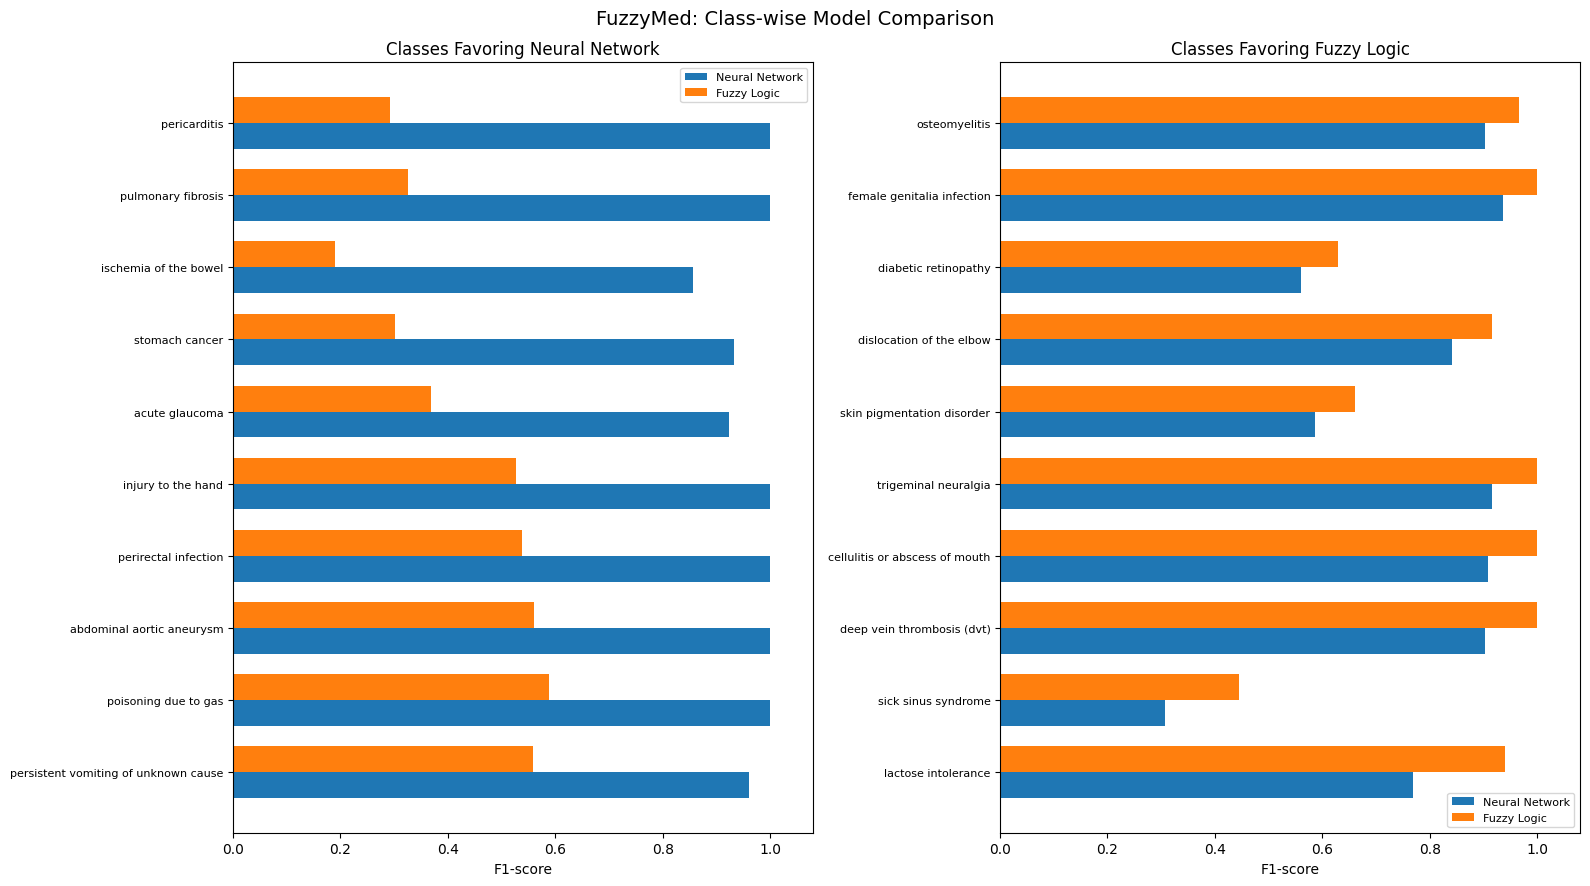

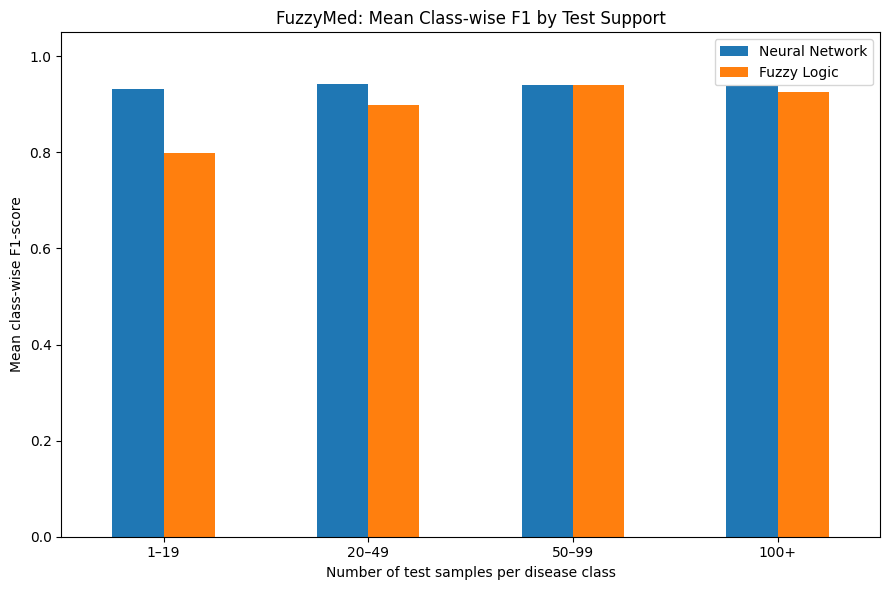

All final graphs and tables saved!
Folder: /content/FuzzyMed_Final_Graphs
ZIP file: /content/FuzzyMed_Final_Graphs.zip


In [52]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report

# Create a folder for the final figures
output_dir = "/content/FuzzyMed_Final_Graphs"
os.makedirs(output_dir, exist_ok=True)

y_true = np.asarray(yte)
nn_predictions = np.asarray(nn_pred)
fuzzy_predictions = np.asarray(fuzzy_pred)

assert len(y_true) == len(nn_predictions) == len(fuzzy_predictions)

# Generate fresh class-wise evaluation reports
nn_report = classification_report(
    y_true, nn_predictions, output_dict=True, zero_division=0
)
fuzzy_report = classification_report(
    y_true, fuzzy_predictions, output_dict=True, zero_division=0
)

# Overall evaluation metrics
metrics = {
    "Accuracy": [
        np.mean(nn_predictions == y_true),
        np.mean(fuzzy_predictions == y_true)
    ],
    "Macro Precision": [
        nn_report["macro avg"]["precision"],
        fuzzy_report["macro avg"]["precision"]
    ],
    "Macro Recall": [
        nn_report["macro avg"]["recall"],
        fuzzy_report["macro avg"]["recall"]
    ],
    "Macro F1": [
        nn_report["macro avg"]["f1-score"],
        fuzzy_report["macro avg"]["f1-score"]
    ],
    "Weighted F1": [
        nn_report["weighted avg"]["f1-score"],
        fuzzy_report["weighted avg"]["f1-score"]
    ]
}

results = pd.DataFrame(
    metrics, index=["Neural Network", "Fuzzy Logic"]
)

# -----------------------------------------
# FIGURE 1: Overall performance comparison
# -----------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

selected = ["Accuracy", "Macro F1", "Weighted F1"]
x = np.arange(len(selected))
width = 0.34

for i, model in enumerate(results.index):
    values = results.loc[model, selected].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=model)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("FuzzyMed: Overall Model Performance")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(selected)
ax.set_ylim(0, 1.12)
ax.legend()
fig.tight_layout()
fig.savefig(f"{output_dir}/01_overall_model_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 2: Precision, recall and F1
# -----------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

selected = ["Macro Precision", "Macro Recall", "Macro F1"]
x = np.arange(len(selected))

for i, model in enumerate(results.index):
    values = results.loc[model, selected].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=model)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("FuzzyMed: Macro-Averaged Metrics")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(selected)
ax.set_ylim(0, 1.12)
ax.legend()
fig.tight_layout()
fig.savefig(f"{output_dir}/02_precision_recall_f1.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# Build a class-wise comparison table
# -----------------------------------------
class_rows = []

for key, nn_values in nn_report.items():
    if not isinstance(nn_values, dict) or "f1-score" not in nn_values:
        continue
    if key not in fuzzy_report or not isinstance(fuzzy_report[key], dict):
        continue
    if "f1-score" not in fuzzy_report[key]:
        continue

    try:
        class_id = int(key)
    except (ValueError, TypeError):
        continue

    # Convert encoded IDs back to disease names when available
    if "label_encoder" in globals():
        disease = str(label_encoder.classes_[class_id])
    else:
        disease = str(class_id)

    class_rows.append({
        "Class_ID": class_id,
        "Disease": disease,
        "Support": int(nn_values["support"]),
        "NN_F1": nn_values["f1-score"],
        "Fuzzy_F1": fuzzy_report[key]["f1-score"]
    })

class_df = pd.DataFrame(class_rows)
class_df["F1_Difference"] = class_df["NN_F1"] - class_df["Fuzzy_F1"]

# -----------------------------------------
# FIGURE 3: Classes where each model excels
# -----------------------------------------
nn_advantage = class_df.nlargest(10, "F1_Difference")
fuzzy_advantage = class_df.nsmallest(10, "F1_Difference")

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

for ax, subset, title in [
    (axes[0], nn_advantage, "Classes Favoring Neural Network"),
    (axes[1], fuzzy_advantage, "Classes Favoring Fuzzy Logic")
]:
    subset = subset.sort_values("F1_Difference")
    positions = np.arange(len(subset))
    h = 0.36

    ax.barh(positions - h/2, subset["NN_F1"], h, label="Neural Network")
    ax.barh(positions + h/2, subset["Fuzzy_F1"], h, label="Fuzzy Logic")

    ax.set_yticks(positions)
    ax.set_yticklabels(subset["Disease"], fontsize=8)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("F1-score")
    ax.set_title(title)
    ax.legend(fontsize=8)

fig.suptitle("FuzzyMed: Class-wise Model Comparison", fontsize=14)
fig.tight_layout()
fig.savefig(f"{output_dir}/03_classwise_f1_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# -----------------------------------------
# FIGURE 4: Performance by test-set support
# -----------------------------------------
class_df["Support Group"] = pd.cut(
    class_df["Support"],
    bins=[0, 19, 49, 99, np.inf],
    labels=["1–19", "20–49", "50–99", "100+"]
)

grouped = class_df.groupby(
    "Support Group", observed=False
)[["NN_F1", "Fuzzy_F1"]].mean()

fig, ax = plt.subplots(figsize=(9, 6))
grouped.plot(kind="bar", ax=ax)

ax.set_title("FuzzyMed: Mean Class-wise F1 by Test Support")
ax.set_xlabel("Number of test samples per disease class")
ax.set_ylabel("Mean class-wise F1-score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=0)
ax.legend(["Neural Network", "Fuzzy Logic"])
fig.tight_layout()
fig.savefig(f"{output_dir}/04_f1_by_class_support.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Save supporting tables
results.to_csv(f"{output_dir}/final_evaluation.csv")
class_df.to_csv(f"{output_dir}/classwise_f1_comparison.csv", index=False)
grouped.to_csv(f"{output_dir}/f1_by_class_support.csv")

# Package all figures and tables into one ZIP
zip_path = "/content/FuzzyMed_Final_Graphs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(output_dir):
        archive.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("All final graphs and tables saved!")
print("Folder:", output_dir)
print("ZIP file:", zip_path)
